In [16]:
import sklearn as sk

In [17]:
import platform
import numpy as np
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.font_manager as fm
import warnings
warnings.filterwarnings('ignore')


# OS에 따라서 폰트 로드
os_name = platform.system()

if os_name == 'Linux':
    # 리눅스용 폰트 로드
    plt.rc('font', family='NanumGothicCoding')
    print("(리눅스) 한글폰트 로드 완료")

elif os_name == 'Windows':
    # 윈도우용 폰트 로드
    font_path = 'C:\\Windows\\Fonts\\malgun.ttf'
    font = fm.FontProperties(fname=font_path).get_name()
    mpl.rc('font', family=font)
    print("(윈도우) 한글폰트 로드 완료")

elif os_name == 'Darwin':
    # 맥용 폰트 로드
    plt.rc('font', family='AppleGothic')
    print("(맥) 한글폰트 로드 완료")

else:
    print(f"알 수 없는 OS입니다: {os_name}")

# 마이너스 기호 깨짐 방지
mpl.rcParams['axes.unicode_minus'] = False

(윈도우) 한글폰트 로드 완료


In [18]:
import pandas as pd

data = pd.read_csv('./AICE Associate 샘플문항_분류/wine_quality_data.csv')
data.head(4)

,Grade,E_title,E_country,E_province,E_region_1,E_region_2,E_winery,E_FE_vintage,E_wine_variety,E_FE_wine_kind,FE_continent,E_price,FE_points_location,FE_points_variety,FE_points_winery
0,Fail,Nicosia 2013 Vulkà Bianco (Etna),Italy,Sicily & Sardinia,Etna,-,Nicosia,2013,White Blend,white,0,NaN,90.0,87.0,87.0
1,Fail,Quinta dos Avidagos 2011 Avidagos Red (Douro),Portugal,Douro,-,-,Quinta dos Avidagos,2011,Port,NaN,0,15.0,89.0,88.0,87.0
2,Fail,St. Julian 2013 Reserve Late Harvest Riesling ...,US,Michigan,Lake Michigan Shore,-,St. Julian,2013,Riesling,white|sparkling,1,13.0,86.0,90.0,86.0
3,Fail,Tandem 2011 Ars In Vitro Tempranillo-Merlot (N...,Spain,Northern Spain,Navarra,-,Tandem,2011,Merlot,red|rose|sparkling,0,15.0,86.0,87.0,87.0


Text(0.5, 1.0, 'Winery Score')

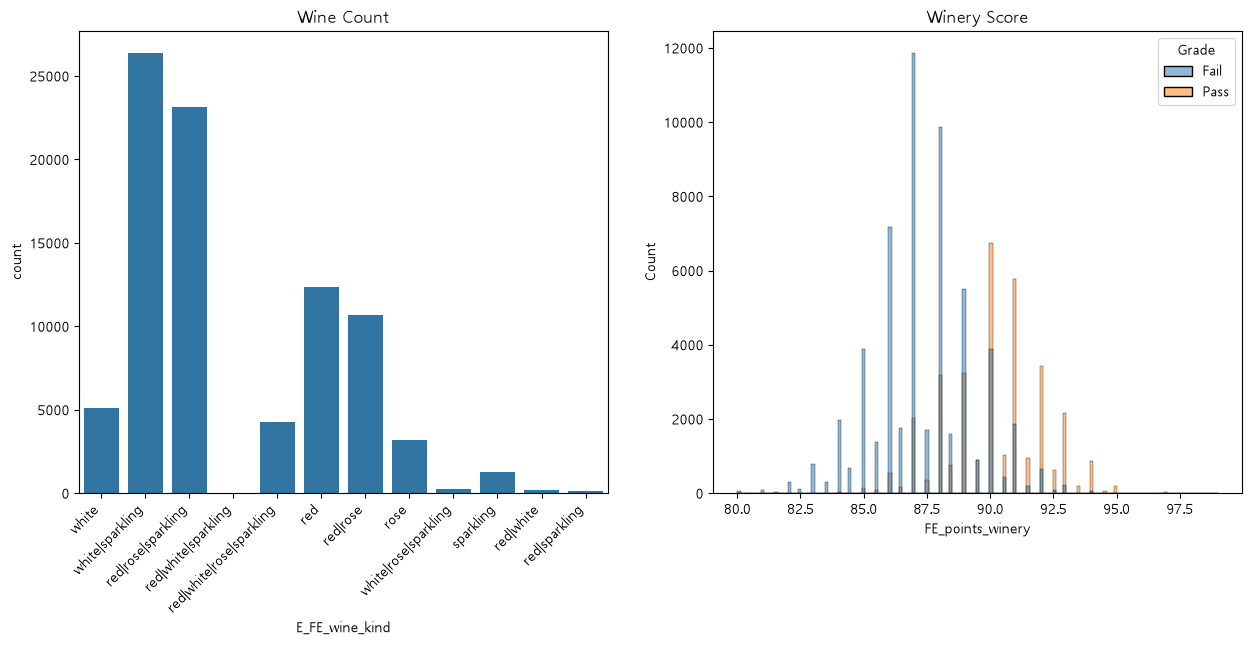

In [19]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15,6))

sns.countplot(data=data, x='E_FE_wine_kind', ax=axes[0])
sns.histplot(data=data, x='FE_points_winery', hue='Grade', ax=axes[1])

plt.setp(axes[0].get_xticklabels(), rotation=45, ha='right')

axes[0].set_title('Wine Count')
axes[1].set_title('Winery Score')

<Axes: xlabel='Grade', ylabel='FE_points_winery'>

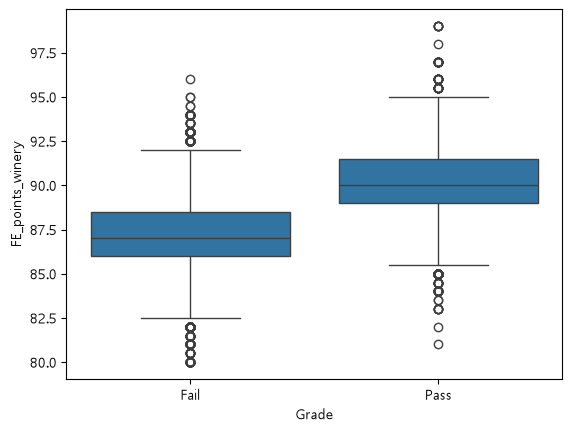

In [20]:
sns.boxplot(data=data, x='Grade', y='FE_points_winery')

In [ ]:
q1 = data['FE_points_winery'].quantile(0.25)
q3 = data['FE_points_winery'].quantile(0.75)
iqr = q3 - q1

upper_fence = q3 + 1.5 * iqr
lower_fence = q1 - 1.5 * iqr

data_temp = data.drop(data[(data['FE_points_winery'] < lower_fence)|(data['FE_points_winery'] > upper_fence)].index, axis = 0)
data_temp = data_temp.drop(columns=['E_title'])
data_temp.reset_index(drop=True, inplace=True)

In [26]:
print(data_temp.isnull().sum())
data_na = data_temp.dropna()

Grade                    0
E_country                0
E_province               0
E_region_1               0
E_region_2               0
E_winery                 0
E_FE_vintage             0
E_wine_variety           0
E_FE_wine_kind        3746
FE_continent             0
E_price               6902
FE_points_location       0
FE_points_variety        0
FE_points_winery         0
dtype: int64


In [ ]:
data_na.loc[data_na['E_FE_wine_kind'].isin(['white|rose|sparkling','red|white|sparkling', 'red|white|rose|sparkling', 'red|sparkling']),['E_FE_wine_kind']] = 'sparkling'
data_na.loc[data_na['E_FE_wine_kind'].isin(['white|sparkling']),['E_FE_wine_kind']] = 'white'
data_na.loc[data_na['E_FE_wine_kind'].isin(['red|rose', 'red|white', 'red|rose|sparkling']),['E_FE_wine_kind']] = 'red'

print(data_na['E_FE_wine_kind'].value_counts())

data_na = data_na.drop(columns=['E_province', 'E_region_1', 'E_region_2', 'E_winery', 'E_wine_variety'])
data_preset = pd.get_dummies(data=data_na, columns=['E_country', 'E_FE_wine_kind'])
data_preset.info()

KeyError: 'E_FE_wine_kin'

In [ ]:
from sklearn.model_selection import train_test_split

X = data_preset.drop('Grade', axis=1)
y = data_preset['Grade']

X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.3, random_state=7, stratify= y)


In [ ]:
from sklearn.preprocessing import StandardScaler

ss = StandardScaler()

X_train = ss.fit_transform(X_train)
X_valid = ss.transform(X_valid)

print(round(np.max(X_valid)))